Initial Dataset Shape: (123107, 13)
Data Cleaning Complete. Missing values handled.

--- Customer Segment Profiles ---


recency frequency  monetary                 
                         mean      mean      mean        sum count
segment                                                           
At-Risk / Churn Risk   413.38      2.75   6346.15   19622306  3092
Champions              293.57      4.88  13079.69  105592349  8073
Potential Loyalists    179.17      7.96  22449.64  143340955  6385
Recent / Low Spenders   25.65      6.27  16996.47   66099290  3889

/tmp/ipykernel_537/1253273132.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_sales, x='product_category', y='total_purchase_amount', palette='viridis')
/tmp/ipykernel_537/1253273132.py:134: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_payment, x='payment_method', y='churn', palette='magma')


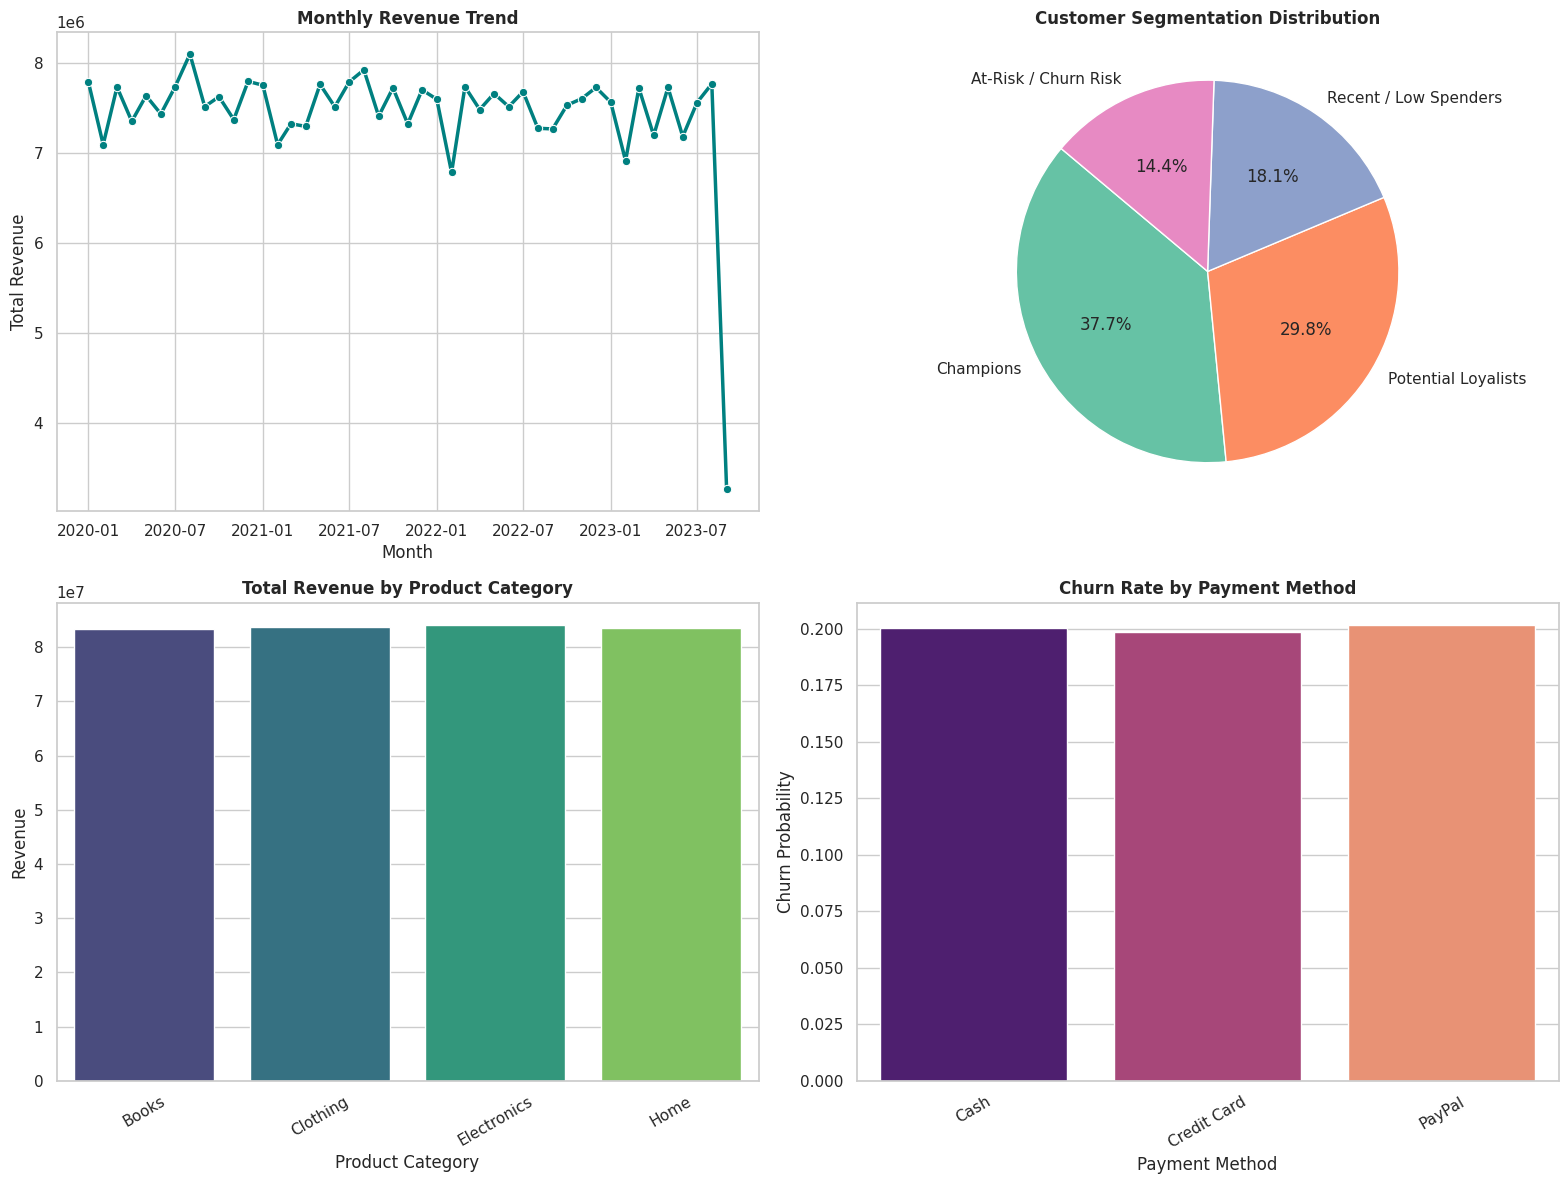


Visualizations generated successfully and saved as 'customer_behavior_analysis_plots.png'.


In [2]:
# ==========================================
# 1. SETUP & LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import datetime as dt

# Styling setup
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==========================================
# 2. DATA LOADING & CLEANING
# ==========================================
# Load dataset (Make sure 'ecommerce_customer_data_large.csv' is uploaded in Colab session)
df = pd.read_csv('ecommerce_customer_data_large.csv')

print(f"Initial Dataset Shape: {df.shape}")

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Convert purchase date to datetime
df['purchase_date'] = pd.to_datetime(df['purchase_date'])

# Handle missing values (e.g., Returns column has some nulls)
df['returns'] = df['returns'].fillna(0)

# Drop redundant columns if any ('age' is duplicate of 'customer_age')
if 'age' in df.columns and 'customer_age' in df.columns:
    df = df.drop(columns=['age'])

print("Data Cleaning Complete. Missing values handled.")

# ==========================================
# 3. FEATURE ENGINEERING & RFM ANALYSIS
# ==========================================
# Set a reference snapshot date for Recency calculation
snapshot_date = df['purchase_date'].max() + dt.timedelta(days=1)

# Group by Customer ID to build RFM (Recency, Frequency, Monetary) metrics
rfm = df.groupby('customer_id').agg({
    'purchase_date': lambda x: (snapshot_date - x.max()).days, # Recency
    'customer_id': 'count',                                    # Frequency
    'total_purchase_amount': 'sum'                             # Monetary
}).rename(columns={
    'purchase_date': 'recency',
    'customer_id': 'frequency',
    'total_purchase_amount': 'monetary'
}).reset_index()

# Merge RFM back into the main dataframe
df = pd.merge(df, rfm, on='customer_id', how='left')

# ==========================================
# 4. CUSTOMER SEGMENTATION (K-MEANS CLUSTERING)
# ==========================================
# Prepare features for clustering
rfm_clustering_data = rfm[['recency', 'frequency', 'monetary']].copy()

# Log transform to normalize skewed financial data
rfm_log = np.log1p(rfm_clustering_data)

# Scale features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Apply K-Means Clustering (k=4 segments)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['cluster'] = kmeans.fit_predict(rfm_scaled)

# Map clusters to descriptive business segment names
cluster_labels = {
    0: 'At-Risk / Churn Risk',
    1: 'Potential Loyalists',
    2: 'Champions',
    3: 'Recent / Low Spenders'
}
rfm['segment'] = rfm['cluster'].map(cluster_labels)

# Merge segment back to main df
df = pd.merge(df, rfm[['customer_id', 'segment']], on='customer_id', how='left')

# Print Segment Summary Profiles
segment_profile = rfm.groupby('segment').agg({
    'recency': 'mean',
    'frequency': 'mean',
    'monetary': ['mean', 'sum', 'count']
}).round(2)

print("\n--- Customer Segment Profiles ---")
display(segment_profile)

# ==========================================
# 5. PURCHASE PATTERNS & RETENTION VISUALIZATIONS
# ==========================================
# Extract extra time features for plotting
df['purchase_year_month'] = df['purchase_date'].dt.to_period('M')
df['purchase_dayofweek'] = df['purchase_date'].dt.day_name()

plt.figure(figsize=(16, 12))

# Plot 1: Monthly Revenue Trend
plt.subplot(2, 2, 1)
monthly_sales = df.groupby(df['purchase_date'].dt.to_period('M'))['total_purchase_amount'].sum().reset_index()
monthly_sales['purchase_date'] = monthly_sales['purchase_date'].dt.to_timestamp()
sns.lineplot(data=monthly_sales, x='purchase_date', y='total_purchase_amount', color='teal', linewidth=2.5, marker='o')
plt.title('Monthly Revenue Trend', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

# Plot 2: Customer Segment Distribution
plt.subplot(2, 2, 2)
segment_counts = rfm['segment'].value_counts()
plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set2"))
plt.title('Customer Segmentation Distribution', fontsize=12, fontweight='bold')

# Plot 3: Purchase Volume by Product Category
plt.subplot(2, 2, 3)
cat_sales = df.groupby('product_category')['total_purchase_amount'].sum().reset_index()
sns.barplot(data=cat_sales, x='product_category', y='total_purchase_amount', palette='viridis')
plt.title('Total Revenue by Product Category', fontsize=12, fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.xticks(rotation=30)

# Plot 4: Churn Rate by Payment Method
plt.subplot(2, 2, 4)
churn_payment = df.groupby('payment_method')['churn'].mean().reset_index()
sns.barplot(data=churn_payment, x='payment_method', y='churn', palette='magma')
plt.title('Churn Rate by Payment Method', fontsize=12, fontweight='bold')
plt.xlabel('Payment Method')
plt.ylabel('Churn Probability')
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('customer_behavior_analysis_plots.png', dpi=300)
plt.show()

print("\nVisualizations generated successfully and saved as 'customer_behavior_analysis_plots.png'.")